In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

## Pulling Data from Yahoo finance: 
* In this example we use AAPL which is Apple stock data. AAPL is the symbol.
* We use **.download()** methord then specify in the brackets with a string of the symbol we want to pull.
* We also have include in the methord() the start date by using parameter **start = '2022-04-14'** and he date in **yyyy-mm-dd** and the
end date's parameter as **end = '2026-10-11'**.
    

In [3]:
apple_stock = yf.download("AAPL", start="2022-01-01", end="2023-01-01", auto_adjust= False)

[*********************100%***********************]  1 of 1 completed


## Complete download:

The msg will display **100% 1 of 1 completed** when data is complete.


In [4]:
apple_stock.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2022-01-03,177.786346,182.009995,182.880005,177.710007,177.830002,104487900
2022-01-04,175.530014,179.699997,182.940002,179.119995,182.630005,99310400
2022-01-05,170.860901,174.919998,180.169998,174.639999,179.610001,94537600
2022-01-06,168.008713,172.000000,175.300003,171.639999,172.699997,96904000
2022-01-07,168.174744,172.169998,174.139999,171.029999,172.889999,86709100


## Column Explaination:
  1. **Price**: Current or last price.
  2.  **Close**: Price at the end of that period.
  3.  **High**: Highest price during that period.
  4.  **Low**: Lowest price at the end of the that period.
  5.  **Open**: Is the price at the start of that period.

-------------------------------------------------------------------------------------------

## New Column to calculate % change in daily return:

* We use the **.pct_change()** module stands for % change and it will calculate this for each day except the first row since the previous days 
records are needed to get the % change.

In [5]:
apple_stock['Daily_Return'] = apple_stock['Adj Close'].pct_change()
apple_stock.head()

Price,Adj Close,Close,High,Low,Open,Volume,Daily_Return
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,
Date,,,,,,,
2022-01-03,177.786346,182.009995,182.880005,177.710007,177.830002,104487900,NaN
2022-01-04,175.530014,179.699997,182.940002,179.119995,182.630005,99310400,-0.012691
2022-01-05,170.860901,174.919998,180.169998,174.639999,179.610001,94537600,-0.026600
2022-01-06,168.008713,172.000000,175.300003,171.639999,172.699997,96904000,-0.016693
2022-01-07,168.174744,172.169998,174.139999,171.029999,172.889999,86709100,0.000988


## Ploting the daily returns:
* We use **Matplotlib** to viz the daily returns.
* 
```mermaid
graph LR
    A(y-axis) --> B(Returns) 
```
```mermaid
graph LR
    A(x-axis) --> B(Dates)
```

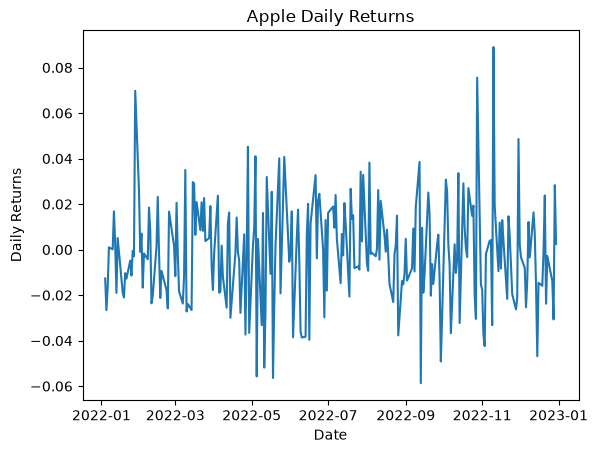

In [6]:
plt.plot(apple_stock['Daily_Return'])
plt.title('Apple Daily Returns')
plt.xlabel('Date')
plt.ylabel('Daily Returns')
plt.show()

The stocks daily returns flactuate around zero which is pretty normal for a stable stock.

## Moving AVG:

* A moving average is the average of a set number of recent prices. It “moves” forward over time: when a new price is added, the oldest price in the set is dropped. It helps show the general price trend by smoothing out short-term ups and downs.

* The window selects how many values to use to calcualte the moving avg, if its 5 it will take 5 values then calculate and so on. If a new value is added the oldest one will be dropped and the newest one will be added to make it a window of 5.

In [7]:
apple_stock['50-MA'] = apple_stock['Adj Close'].rolling(window= 50).mean()
apple_stock.tail()

Price,Adj Close,Close,High,Low,Open,Volume,Daily_Return,50-MA
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,,
Date,,,,,,,,
2022-12-23,129.547668,131.860001,132.419998,129.639999,130.919998,63814900,-0.002798,141.532723
2022-12-27,127.749771,130.029999,131.410004,128.720001,131.380005,69007800,-0.013878,141.373156
2022-12-28,123.829750,126.040001,131.029999,125.870003,129.669998,85438400,-0.030685,141.056131
2022-12-29,127.337128,129.610001,130.479996,127.730003,127.989998,75703700,0.028324,140.782969
2022-12-30,127.651497,129.929993,129.949997,127.430000,128.410004,77034200,0.002469,140.513935


---

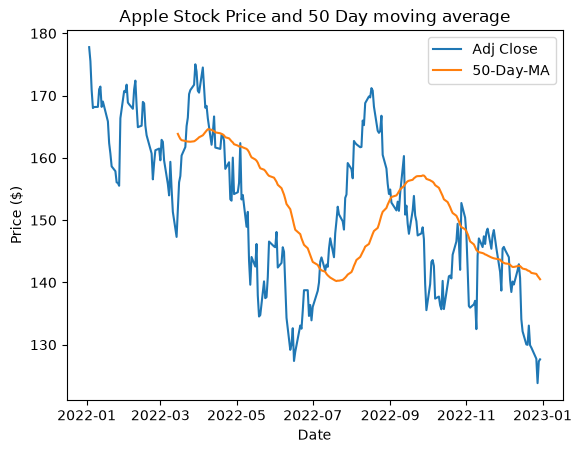

In [8]:
plt.plot(apple_stock['Adj Close'], label = 'Adj Close')
plt.plot(apple_stock['50-MA'], label ='50-Day-MA')
plt.title('Apple Stock Price and 50 Day moving average')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

The yellow line represents the 50-MA and it starts where its start cause our MA window is 50 days and we don't have the previous combined 100 days of data to calculate the previous 50 days.

---

## Volatility: 
* Volatility means how much and how quickly a price changes over time.
* A highly volatile price has bigger or more frequent ups and downs, meaning its more risky. 
* A low-volatility price tends to move more steadily less risky.

In [9]:
volatility = apple_stock['Daily_Return'].std()
print(f'Volatility: {volatility}')

Volatility: 0.022471303189548045


This is a good measure cause the higher the result the higher the volatility meaning it changes frequently and unpredictable.

---

## Sharp Ratio:
* Compares how much the investment has earned compared to how much its returns have bounced around
* Basically: 
```mermaid
graph TB;
    A(“Was the return worth the ups and downs?”)
```

* A higher Sharpe ratio means more return for each unit of volatility.
* Lower Sharpe ratio means less return for amount of volatility.
* A ratio greater than one is generally considered good.

In [10]:
risk_free_rate = 0.01
annual_return = (apple_stock['Daily_Return'].mean()+ 1) ** 252 - 1
annual_volatility = apple_stock['Daily_Return'].std() * np.sqrt(252)
sharpe_ratio = (annual_return - risk_free_rate) / annual_volatility
print(f'Sharpe Ratio: {sharpe_ratio}')


Sharpe Ratio: -0.6927817306861621


Not that good a sharpe ratio

## Getting SnP 500 data:
* We will use the sp500 stock data as a benchmark, to refrence how the broder U.S. stock market peformed.  
* So comparing the daily stock of apple on the say day as the combined snp 500 helps show wheather the stock did better or worse than the market on the same day.

In [11]:
sp500 = yf.download('^GSPC', start='2022-02-02', 
                    end='2023-01-01', 
                    auto_adjust=False)

[*********************100%***********************]  1 of 1 completed


In [12]:
sp500.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,
2022-02-02,4589.379883,4589.379883,4595.310059,4544.319824,4566.390137,4481580000
2022-02-03,4477.439941,4477.439941,4542.879883,4470.390137,4535.410156,4401970000
2022-02-04,4500.529785,4500.529785,4539.660156,4451.500000,4482.790039,4706290000
2022-02-07,4483.870117,4483.870117,4521.859863,4471.470215,4505.750000,4228480000
2022-02-08,4521.540039,4521.540039,4531.319824,4465.399902,4480.020020,4459620000


In [13]:
sp500['Daily_Return_SP500'] = sp500['Adj Close'].pct_change()
sp500.head()

Price,Adj Close,Close,High,Low,Open,Volume,Daily_Return_SP500
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,
Date,,,,,,,
2022-02-02,4589.379883,4589.379883,4595.310059,4544.319824,4566.390137,4481580000,NaN
2022-02-03,4477.439941,4477.439941,4542.879883,4470.390137,4535.410156,4401970000,-0.024391
2022-02-04,4500.529785,4500.529785,4539.660156,4451.500000,4482.790039,4706290000,0.005157
2022-02-07,4483.870117,4483.870117,4521.859863,4471.470215,4505.750000,4228480000,-0.003702
2022-02-08,4521.540039,4521.540039,4531.319824,4465.399902,4480.020020,4459620000,0.008401


## Join Using Pandas:
* We join out tbls Daily returns into one using the pandas concat methord droping all nan columns.
* We are only joining the 'Daily Return' columns of the SP500 and the apple_stock data. 

In [14]:
joined_data = pd.concat([apple_stock['Daily_Return'], 
                         sp500['Daily_Return_SP500']], 
                        axis=1).dropna()


In [15]:
joined_data.head()

,Daily_Return,Daily_Return_SP500
Date,,
2022-02-03,-0.016720,-0.024391
2022-02-04,-0.001679,0.005157
2022-02-07,-0.004235,-0.003702
2022-02-08,0.018467,0.008401
2022-02-09,0.008294,0.014517


## Beta:
* Measures how much the stocks returns tend to move in relation to the overall market. 
### Beta Value:
* **Beta around 1** : Indicates the stock tends to move about as much as the stock.
* **Beta > 1** : tends to move more than the stock market.
* **0 < Beta < 1** : tends to move less than the market.
* **Beta < 0** : has tended to move in the opposite direction. 

### Formula:

---


In [16]:
beta = joined_data.cov().iloc[0,1] / joined_data['Daily_Return_SP500'].var()

In [17]:
print(f'Beta: {beta}')

Beta: 1.2961261183115367


In [18]:
apple_stock['20_MA'] = apple_stock['Adj Close'].rolling(window=20).mean()

In [19]:
apple_stock.head()

Price,Adj Close,Close,High,Low,Open,Volume,Daily_Return,50-MA,20_MA
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,,,
Date,,,,,,,,,
2022-01-03,177.786346,182.009995,182.880005,177.710007,177.830002,104487900,NaN,NaN,NaN
2022-01-04,175.530014,179.699997,182.940002,179.119995,182.630005,99310400,-0.012691,NaN,NaN
2022-01-05,170.860901,174.919998,180.169998,174.639999,179.610001,94537600,-0.026600,NaN,NaN
2022-01-06,168.008713,172.000000,175.300003,171.639999,172.699997,96904000,-0.016693,NaN,NaN
2022-01-07,168.174744,172.169998,174.139999,171.029999,172.889999,86709100,0.000988,NaN,NaN


---


## Bollinger Bands:
* **Upper Band** : 

In [20]:
close = apple_stock[('Adj Close', 'AAPL')]
ma = apple_stock[('20_MA', '')]
std = close.rolling(window=20).std()

apple_stock[('Upper_Band', '')] = ma + 2 * std

In [21]:
apple_stock.tail()

Price,Adj Close,Close,High,Low,Open,Volume,Daily_Return,50-MA,20_MA,Upper_Band
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,,,,
Date,,,,,,,,,,
2022-12-23,129.547668,131.860001,132.419998,129.639999,130.919998,63814900,-0.002798,141.532723,138.194334,149.576885
2022-12-27,127.749771,130.029999,131.410004,128.720001,131.380005,69007800,-0.013878,141.373156,137.497276,149.659051
2022-12-28,123.829750,126.040001,131.029999,125.870003,129.669998,85438400,-0.030685,141.056131,136.754043,150.341088
2022-12-29,127.337128,129.610001,130.479996,127.730003,127.989998,75703700,0.028324,140.782969,135.849195,149.412667
2022-12-30,127.651497,129.929993,129.949997,127.430000,128.410004,77034200,0.002469,140.513935,134.946309,148.145393


In [22]:
apple_stock['Lower_Band'] = ma - 2 * close.rolling(window= 20).std()

In [23]:
apple_stock.tail()

Price,Adj Close,Close,High,Low,Open,Volume,Daily_Return,50-MA,20_MA,Upper_Band,Lower_Band
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,
Date,,,,,,,,,,,
2022-12-23,129.547668,131.860001,132.419998,129.639999,130.919998,63814900,-0.002798,141.532723,138.194334,149.576885,126.811782
2022-12-27,127.749771,130.029999,131.410004,128.720001,131.380005,69007800,-0.013878,141.373156,137.497276,149.659051,125.335500
2022-12-28,123.829750,126.040001,131.029999,125.870003,129.669998,85438400,-0.030685,141.056131,136.754043,150.341088,123.166999
2022-12-29,127.337128,129.610001,130.479996,127.730003,127.989998,75703700,0.028324,140.782969,135.849195,149.412667,122.285723
2022-12-30,127.651497,129.929993,129.949997,127.430000,128.410004,77034200,0.002469,140.513935,134.946309,148.145393,121.747225


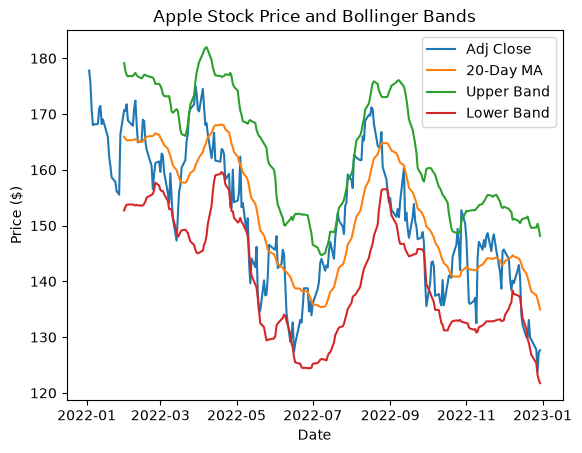

In [28]:
plt.plot(apple_stock['Adj Close'], label = 'Adj Close')
plt.plot(apple_stock['20_MA'], label = '20-Day MA')
plt.plot(apple_stock['Upper_Band'], label = 'Upper Band')
plt.plot(apple_stock['Lower_Band'], label = 'Lower Band')
plt.title('Apple Stock Price and Bollinger Bands')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

---


## Relative Strength Index (RSI):
* Is an indicator that estiamtes how strongly a stocks price has recently been moving up or down. 

In [36]:
delta = apple_stock['Adj Close'].diff(1)
gain = (delta.where(delta > 0,0)).rolling(window = 14).mean()
loss = (-delta.where(delta<0, 0)).rolling(window = 14).mean()

In [38]:
rs = gain / loss

In [39]:
apple_stock['RSI'] = 100 - (100 / (1 + rs))

In [43]:
apple_stock.tail()

Price,Adj Close,Close,High,Low,Open,Volume,Daily_Return,50-MA,20_MA,Upper_Band,Lower_Band,RSI
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,,
Date,,,,,,,,,,,,
2022-12-23,129.547668,131.860001,132.419998,129.639999,130.919998,63814900,-0.002798,141.532723,138.194334,149.576885,126.811782,26.261673
2022-12-27,127.749771,130.029999,131.410004,128.720001,131.380005,69007800,-0.013878,141.373156,137.497276,149.659051,125.335500,27.960336
2022-12-28,123.829750,126.040001,131.029999,125.870003,129.669998,85438400,-0.030685,141.056131,136.754043,150.341088,123.166999,26.152412
2022-12-29,127.337128,129.610001,130.479996,127.730003,127.989998,75703700,0.028324,140.782969,135.849195,149.412667,122.285723,30.302093
2022-12-30,127.651497,129.929993,129.949997,127.430000,128.410004,77034200,0.002469,140.513935,134.946309,148.145393,121.747225,31.430221


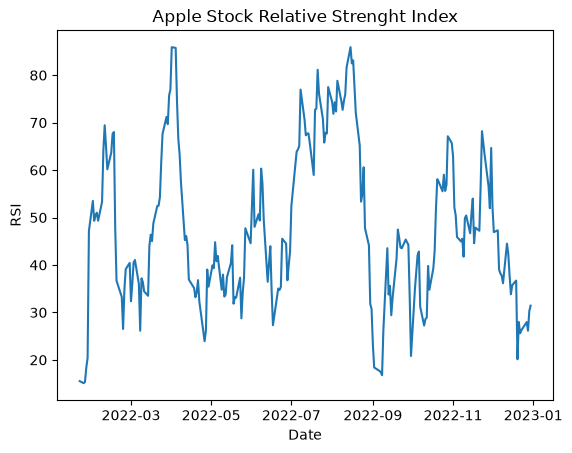

In [44]:
plt.plot(apple_stock['RSI'])
plt.title('Apple Stock Relative Strenght Index')
plt.xlabel('Date')
plt.ylabel('RSI')
plt.show()
